# France - Point par point

Paris listings with some hand-made "dots" mixed in. Goal: find them, split them into letters, read the word.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

pd.set_option('display.width', 200)
df = pd.read_csv('../task_france/paris_listings.csv')
df.shape

(28108, 18)

## EDA

In [2]:
df.info()
df.isna().sum()[lambda s: s > 0]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28108 entries, 0 to 28107
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   listing_id                      28108 non-null  int64  
 1   neighbourhood                   28108 non-null  object 
 2   room_type                       28108 non-null  object 
 3   property_type                   28108 non-null  object 
 4   latitude                        28108 non-null  float64
 5   longitude                       28108 non-null  float64
 6   accommodates                    28108 non-null  int64  
 7   bedrooms                        28103 non-null  float64
 8   beds                            27175 non-null  float64
 9   price                           28108 non-null  float64
 10  minimum_nights                  28010 non-null  float64
 11  availability_365                28108 non-null  int64  
 12  number_of_reviews               

bedrooms            5
beds              933
minimum_nights     98
dtype: int64

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
listing_id,28108.0,5506013.93,2599772.20,1000358.00,3254931.50,5514730.50,7775756.00,9999630.00
latitude,28108.0,48.86,0.02,48.82,48.85,48.86,48.88,48.90
longitude,28108.0,2.34,0.03,2.23,2.32,2.35,2.36,2.46
accommodates,28108.0,3.39,1.83,1.00,2.00,3.00,4.00,16.00
bedrooms,28103.0,1.27,0.89,0.00,1.00,1.00,2.00,33.00
beds,27175.0,1.90,1.16,1.00,1.00,2.00,2.00,30.00
price,28108.0,271.68,200.75,40.00,142.00,214.00,332.67,1500.00
minimum_nights,28010.0,5.75,18.48,1.00,1.00,2.00,3.00,365.00
availability_365,28108.0,192.21,118.83,0.00,77.00,212.00,306.00,365.00
number_of_reviews,28108.0,55.70,90.66,1.00,9.00,27.00,65.00,4760.00


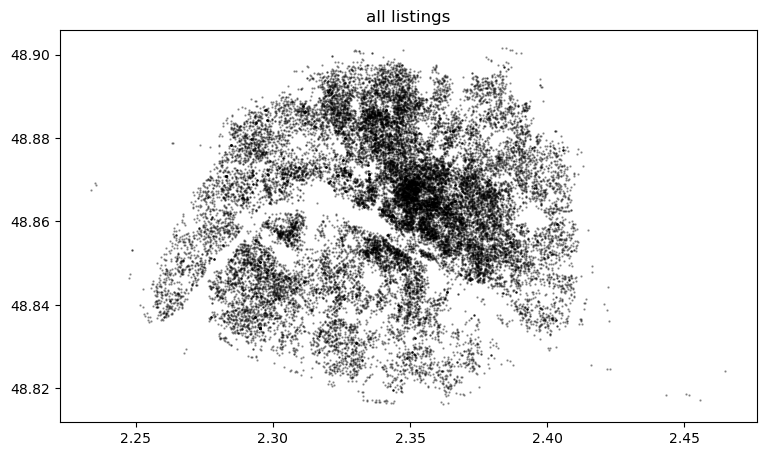

In [4]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df.longitude, df.latitude, s=0.4, c='k', alpha=0.4)
ax.set_aspect(1 / np.cos(np.radians(48.86)))
ax.set_title('all listings')
plt.show()

Nothing odd on the map and nothing odd column by column: no constant values, no impossible combinations (ltm <= total reviews everywhere, room type matches property type, neighbourhood matches coordinates). The fake rows look fine one at a time.

What gave them away: pairs of rows with identical integer fields (room/property type, capacity, beds, minimum nights, review count, ltm, rating, host count) a few hundred metres apart, with price / availability / reviews_per_month only slightly different. Single-listing hosts show up twice, which can't be real.

In [5]:
key_cols = ['room_type', 'property_type', 'accommodates', 'bedrooms', 'beds', 'minimum_nights',
            'number_of_reviews', 'number_of_reviews_ltm', 'host_is_superhost',
            'calculated_host_listings_count', 'review_scores_rating']
key = df[key_cols].astype(str).agg('|'.join, axis=1)
size = key.map(key.value_counts())
pairs = df[(size == 2) & (df.number_of_reviews >= 100) & (df.calculated_host_listings_count == 1)]
pairs.assign(key=key).sort_values('key')[['listing_id', 'latitude', 'longitude', 'price', 'availability_365',
                                         'reviews_per_month', 'number_of_reviews', 'number_of_reviews_ltm']].head(12)

,listing_id,latitude,longitude,price,availability_365,reviews_per_month,number_of_reviews,number_of_reviews_ltm
687,9325331,48.87414,2.34092,496.33,57,2.83,337,16
5817,1643658,48.87277,2.34277,489.30,37,3.00,337,16
11683,8073520,48.86367,2.38049,156.50,315,1.48,161,16
6658,8924591,48.86292,2.36688,154.00,325,1.43,161,16
13527,2006743,48.85710,2.36952,159.00,338,1.27,126,12
14560,7709534,48.86324,2.37321,155.83,320,1.32,126,12
18811,2523837,48.88212,2.32041,147.00,270,0.90,118,12
18572,3552366,48.88272,2.32358,151.00,254,0.89,118,12
12481,1489101,48.88795,2.31570,118.50,294,1.17,111,1
8138,2625580,48.88549,2.31353,115.83,299,1.15,111,1


Following these rows across the map, price, availability and reviews_per_month drift smoothly with position, like a colour gradient. So the injected dots sit on thin curves in the joint space (lon, lat, price, availability, reviews_per_month), while real listings are scattered in it.

Detection: put the five columns on comparable scales (~300 m, 8 % of price, 15 days, 8 % of reviews/month) and take the distance to the 3rd nearest neighbour.

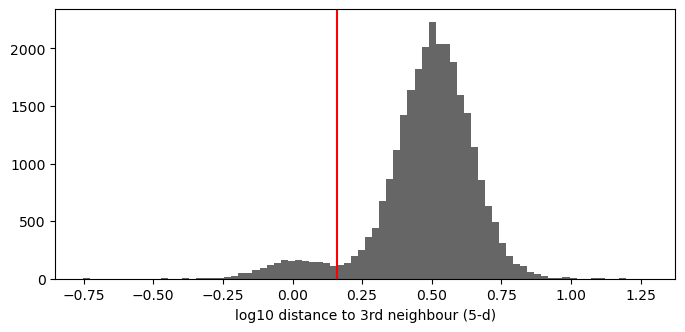

In [6]:
def embed(x):
    return np.c_[x.longitude * 73 / 0.3,          # km east / 0.3
                 x.latitude * 111 / 0.3,          # km north / 0.3
                 np.log(x.price) / 0.08,
                 x.availability_365 / 15,
                 np.log(x.reviews_per_month) / 0.08]

Z = embed(df)
d3 = cKDTree(Z).query(Z, k=4)[0][:, 3]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(d3), bins=80, color='0.4')
ax.axvline(np.log10(1.45), c='r')
ax.set_xlabel('log10 distance to 3rd neighbour (5-d)')
plt.show()

Clearly bimodal. Everything left of the valley (1.45) is a candidate.

1790 candidates


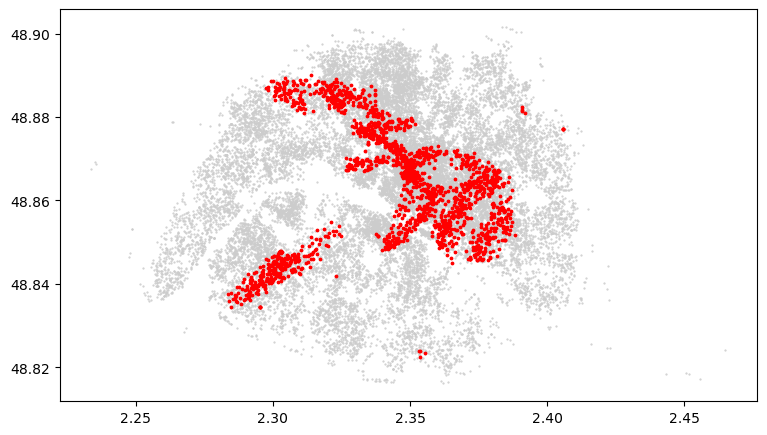

In [7]:
cand = d3 < 1.45
print(cand.sum(), 'candidates')
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df.longitude, df.latitude, s=0.3, c='0.8')
ax.scatter(df.longitude[cand], df.latitude[cand], s=3, c='r')
ax.set_aspect(1 / np.cos(np.radians(48.86)))
plt.show()

On the map the candidates overlap into a tangle, so the letters are not drawn in lat/lon. Cluster them in the same 5-d space instead.

In [8]:
lab = np.full(len(df), -1)
lab[cand] = DBSCAN(eps=2.5, min_samples=3).fit_predict(Z[cand])
counts = pd.Series(lab[lab >= 0]).value_counts()
counts.head(10)

1     332
3     296
2     292
5     273
0     264
4     228
7      13
8       6
6       5
15      4
Name: count, dtype: int64

In [9]:
keep = counts[counts >= 100].index
df['cluster'] = np.where(np.isin(lab, keep), lab, -1)
fake = df[df.cluster >= 0].copy()

def plane(g):
    W = np.c_[g.longitude, g.latitude, np.log(g.price), g.availability_365, np.log(g.reviews_per_month)]
    W = (W - W.mean(0)) / W.std(0)
    return W, PCA(5).fit(W)

rows = []
for c, g in fake.groupby('cluster'):
    W, p = plane(g)
    rows.append((c, len(g), p.explained_variance_ratio_[:2].sum().round(3)))
pd.DataFrame(rows, columns=['cluster', 'n', 'var_2pc'])

,cluster,n,var_2pc
0,0,264,0.965
1,1,332,0.934
2,2,292,0.948
3,3,296,0.962
4,4,228,0.937
5,5,273,0.946


Six groups, 228-332 dots each; the leftovers (a few dozen) are noise. Each group is flat: two principal components explain ~95 % of its variance. So every letter is a 2-d drawing pushed into the five columns by a linear map, a different map per letter.

To look at a letter: PCA to 2-d, whiten, then rotate/mirror until it reads. Whitening takes out the shear, so only rotation and mirror are left; picked by eye from the sheet below.

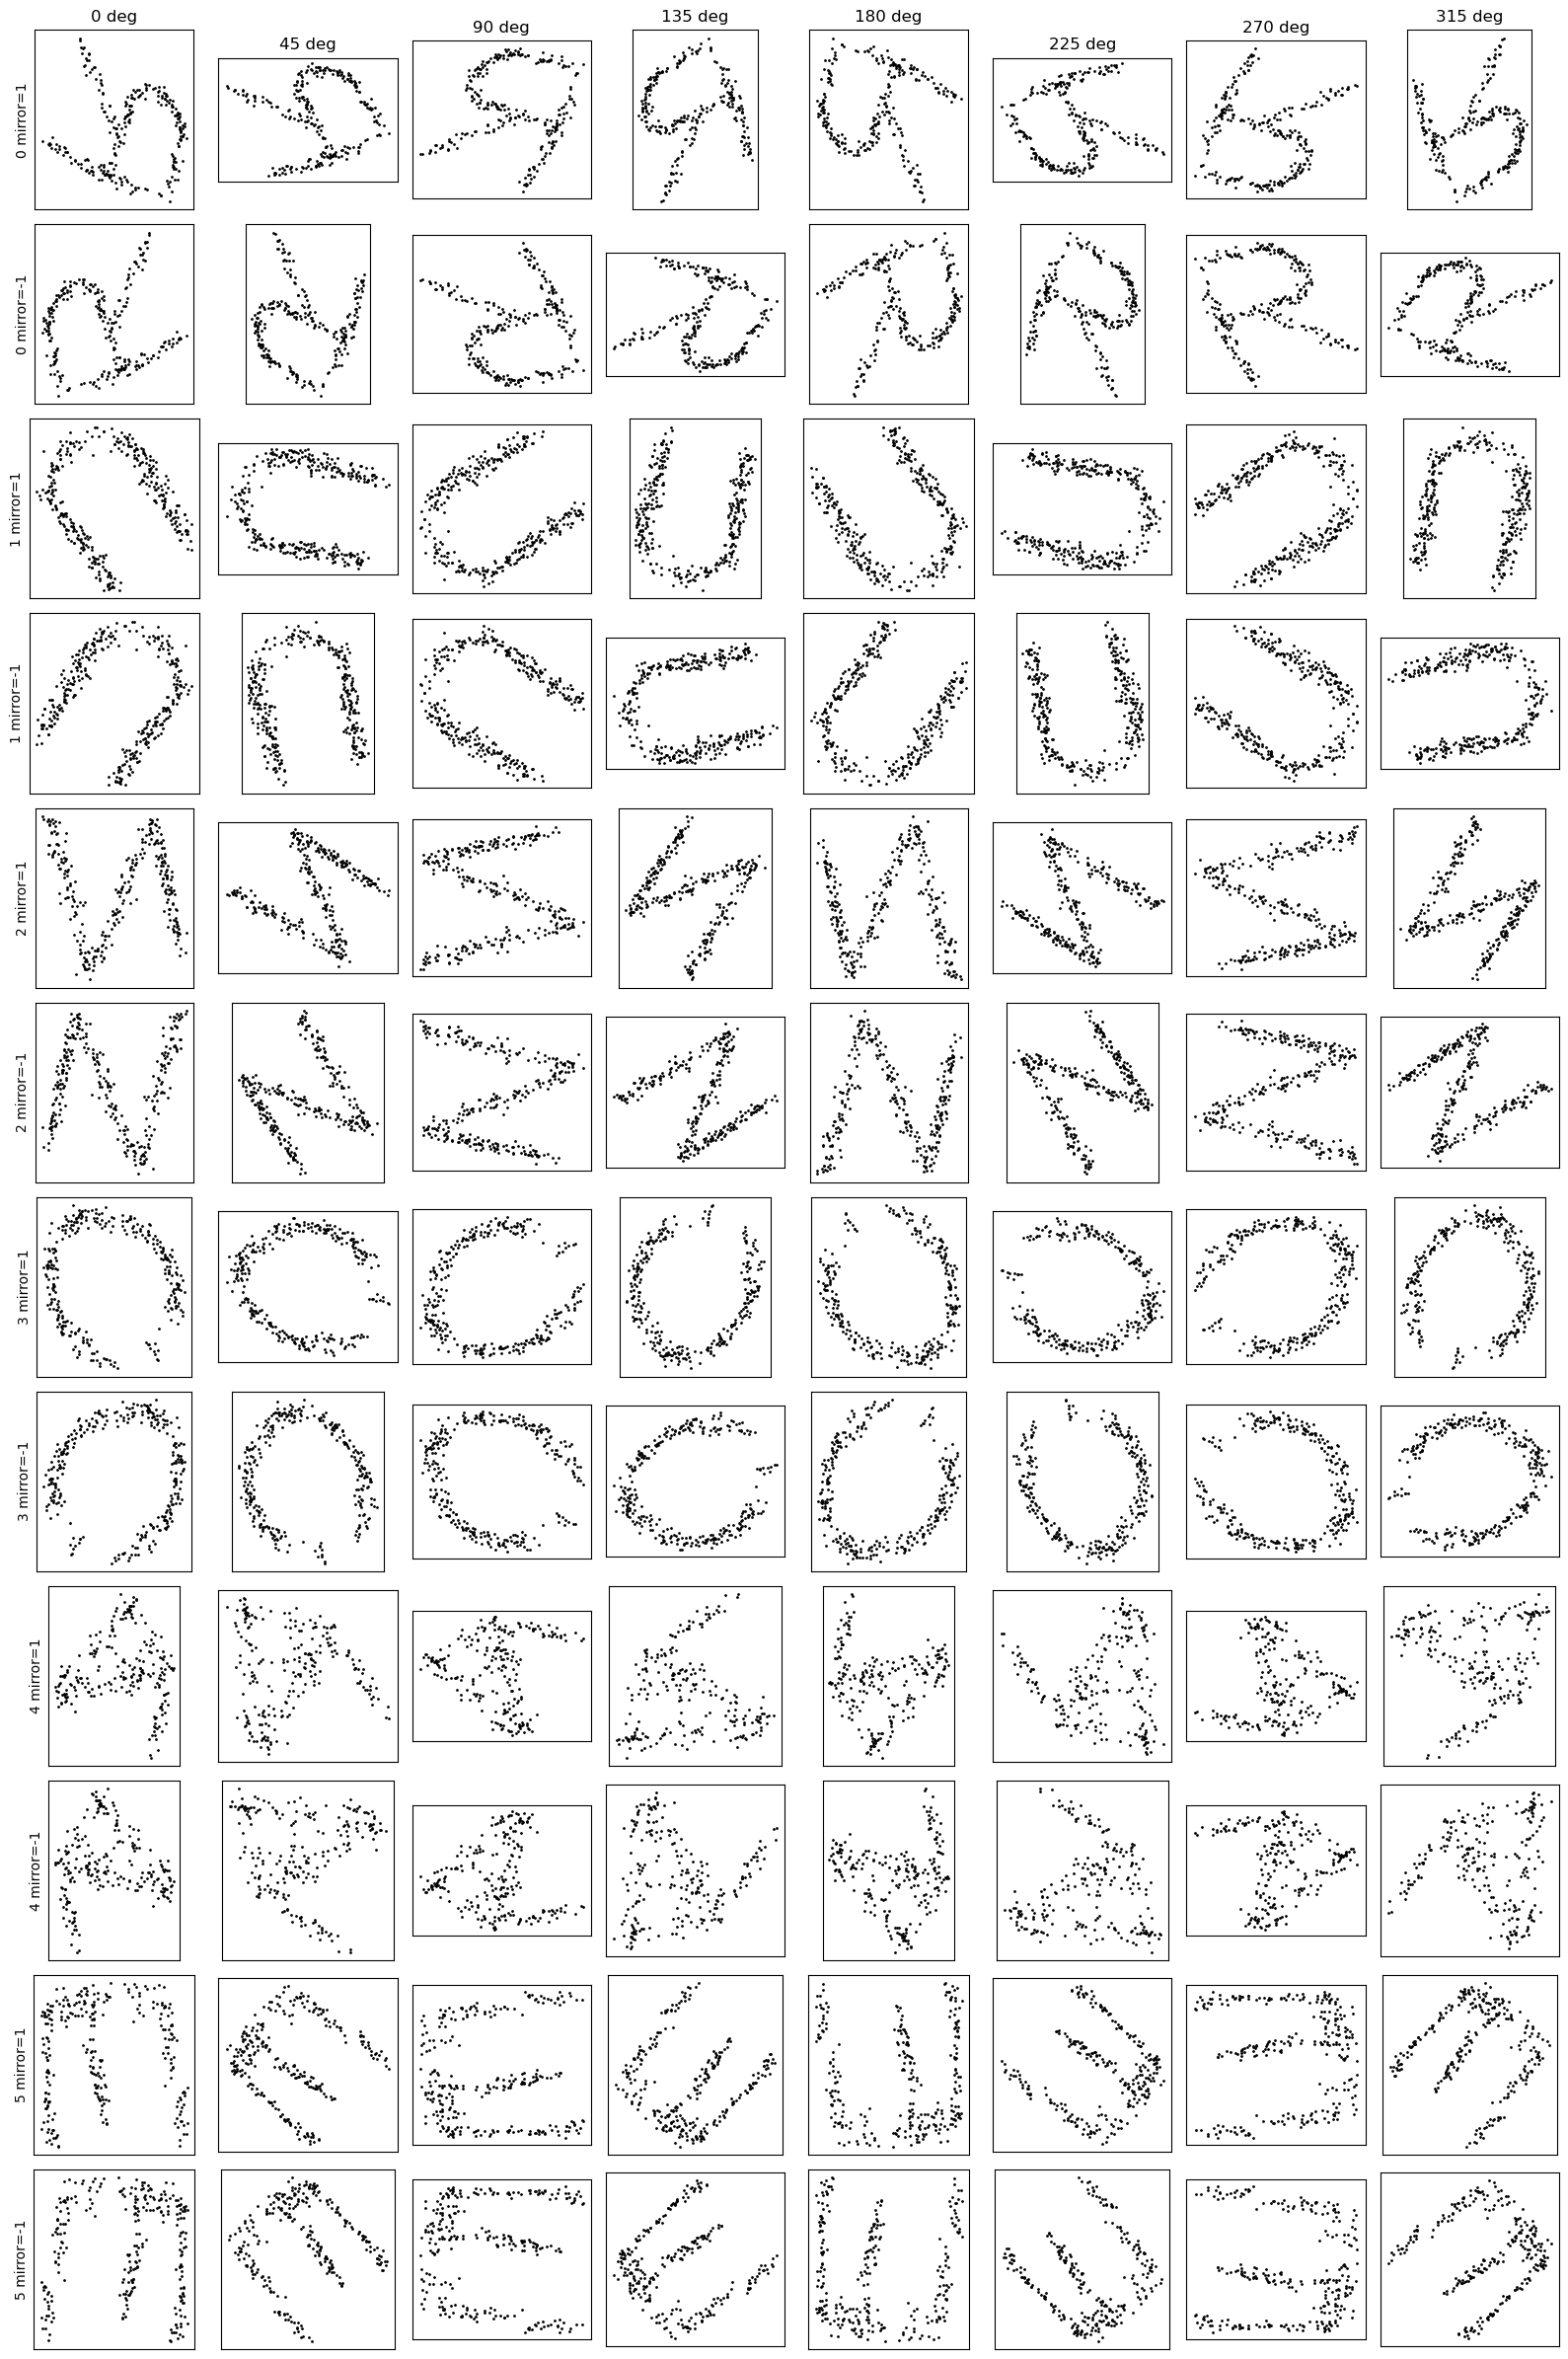

In [10]:
def view(g, ang=0, mirror=1):
    W, _ = plane(g)
    Y = PCA(2, whiten=True).fit_transform(W) * np.array([mirror, 1])
    t = np.radians(ang)
    R = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return Y @ R.T

fig, axs = plt.subplots(12, 8, figsize=(16, 24))
for i, c in enumerate(sorted(keep)):
    g = fake[fake.cluster == c]
    for r, mir in enumerate([1, -1]):
        for k in range(8):
            V = view(g, 45 * k, mir)
            a = axs[2 * i + r, k]
            a.scatter(V[:, 0], V[:, 1], s=1, c='k')
            a.set_aspect('equal'); a.set_xticks([]); a.set_yticks([])
            if k == 0: a.set_ylabel(f'{c} mirror={mir}')
            if i == 0 and r == 0: a.set_title(f'{45 * k} deg')
plt.tight_layout()
plt.show()

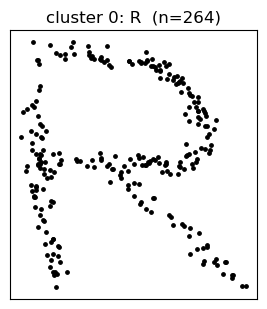

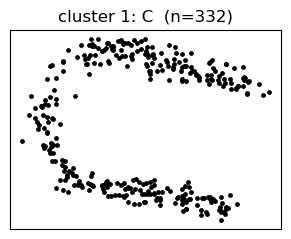

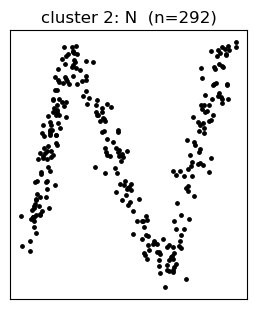

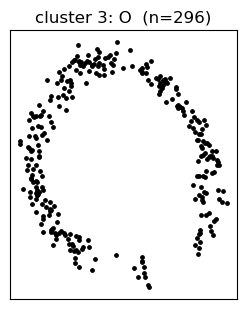

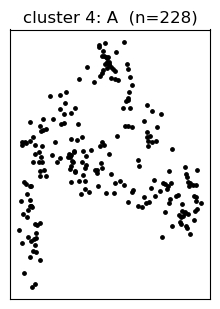

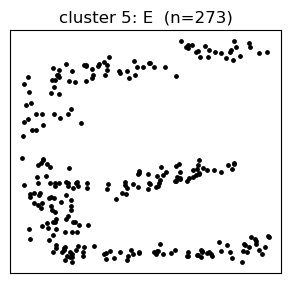

In [11]:
orient = {0: (250, -1), 1: (45, 1), 2: (0, -1), 3: (45, -1), 4: (-10, -1), 5: (90, 1)}
letter = {0: 'R', 1: 'C', 2: 'N', 3: 'O', 4: 'A', 5: 'E'}

for c in sorted(keep):
    g = fake[fake.cluster == c]
    V = view(g, *orient[c])
    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    ax.scatter(V[:, 0], V[:, 1], s=6, c='k')
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'cluster {c}: {letter[c]}  (n={len(g)})')
    plt.savefig(f'letter_{c}_{letter[c]}.png', dpi=120, bbox_inches='tight')
    plt.show()

Readings:
- 0: R (round bowl, straight stem, leg)
- 1: C (open arc with a wide gap)
- 2: N (three straight strokes; Z is the same shape turned 90 degrees, N is the one that makes a word)
- 3: O (closed ring; the small gap fills in with a looser threshold)
- 4: A (sharp apex, crossbar, two legs; the noisiest one)
- 5: E (spine and three parallel bars)

Letters {C, O, R, N, E, A}. I found no column that orders the six groups (centroid positions, colours, ids, row order all tried), so the order comes from the letters themselves: the only word they make is CORNEA, which fits the story (the eye joining the dots).

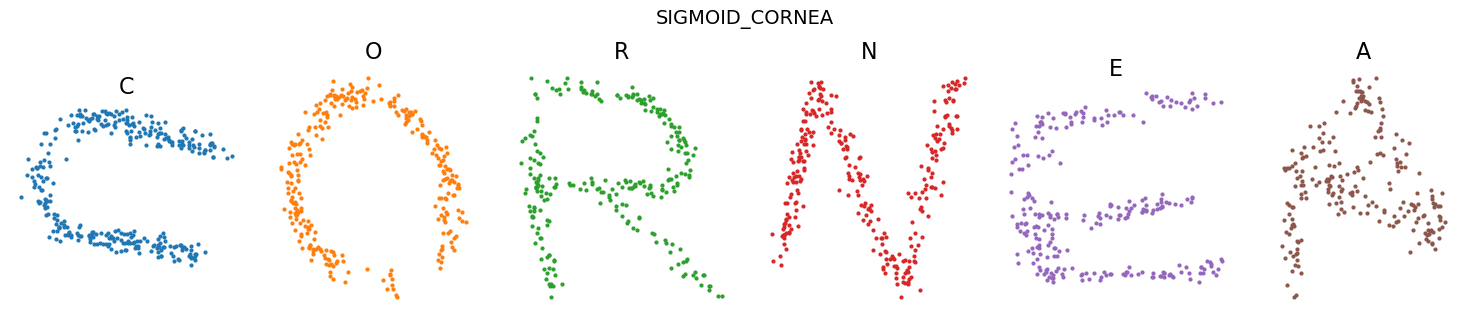

In [12]:
word = 'CORNEA'
order = {1: 0, 3: 1, 0: 2, 2: 3, 5: 4, 4: 5}

fig, axs = plt.subplots(1, 6, figsize=(15, 3.2))
for c, pos in order.items():
    g = fake[fake.cluster == c]
    V = view(g, *orient[c])
    a = axs[pos]
    a.scatter(V[:, 0], V[:, 1], s=4, color=plt.cm.tab10(pos))
    a.set_aspect('equal'); a.axis('off')
    a.set_title(letter[c], fontsize=16)
fig.suptitle('SIGMOID_' + word, fontsize=14)
plt.tight_layout()
plt.savefig('word.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
labels = fake[['listing_id', 'cluster']].copy()
labels['letter'] = labels.cluster.map(letter)
labels['position'] = labels.cluster.map(order) + 1
labels = labels.sort_values(['position', 'listing_id'])
labels.to_csv('labels.csv', index=False)
print(labels.shape)
labels.groupby(['position', 'letter']).size()

(1685, 4)


position  letter
1         C         332
2         O         296
3         R         264
4         N         292
5         E         273
6         A         228
dtype: int64

In [14]:
print('SIGMOID_' + word)

SIGMOID_CORNEA
